# 5. Where the model fails, and why it can't be patched afterwards

**Life Expectancy Predictor · notebook 5 of 7**

An average miss of 2.1 years hides a lot. This notebook uses the unseen-country predictions saved in notebook 3 to ask: which countries does the model get badly wrong, is there a pattern, and can the mistakes be corrected after the fact? The short answer to the last question is no, and understanding why is the most useful thing in this notebook.

## Step 1: Is the error spread evenly?

**What we are looking for.** Whether the 2.1-year average is "every country is off by about two years" or "most countries are close and a few are far off".

Project folder: nb


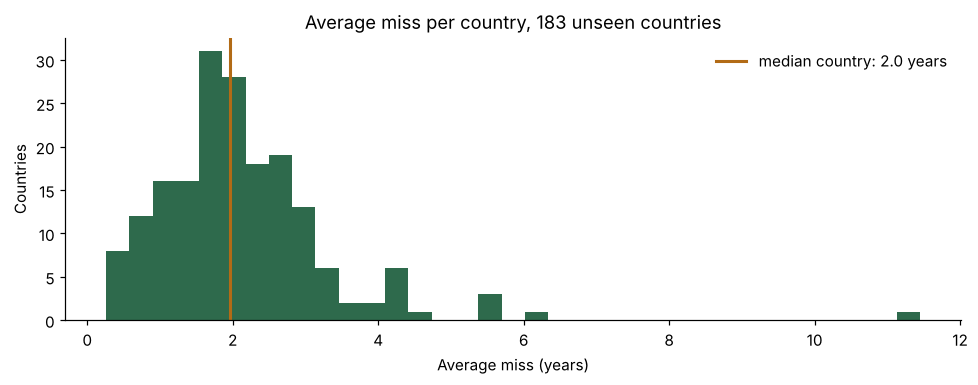

Countries missed by more than 3 years: 26 of 183 (14%)
The worst 18 countries (10%) account for 22% of all error.


In [1]:
# Setup: find the project folder and load the project's own code and settings.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config_loader import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config = load_config(str(ROOT / "config" / "who_life_expectancy.yaml"), base_dir=str(ROOT))

def results(name):
    """Load one of the saved results files in model/."""
    return json.loads((ROOT / "model" / f"{name}.json").read_text(encoding="utf-8"))

print("Project folder:", ROOT.name)
oof = pd.read_csv("oof_predictions.csv")           # each country predicted while unseen (notebook 3)
oof["miss"] = (oof["oof_prediction"] - oof["truth"]).abs()
per_country = oof.groupby("Country").agg(average_miss=("miss", "mean"),
                                          true_life_expectancy=("truth", "mean"),
                                          predicted=("oof_prediction", "mean")).sort_values("average_miss", ascending=False)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(per_country["average_miss"], bins=35, color="#2E6A4C")
ax.axvline(per_country["average_miss"].median(), color="#B26B16", lw=2, label=f"median country: {per_country['average_miss'].median():.1f} years")
ax.set(title="Average miss per country, 183 unseen countries", xlabel="Average miss (years)", ylabel="Countries")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

worst = per_country.head(18)
print(f"Countries missed by more than 3 years: {(per_country['average_miss'] > 3).sum()} of 183 ({(per_country['average_miss'] > 3).mean():.0%})")
print(f"The worst 18 countries (10%) account for {oof[oof.Country.isin(worst.index)]['miss'].sum() / oof['miss'].sum():.0%} of all error.")

**How to read it.** Each bar counts countries by their average miss over 16 years. The orange line is the typical (median) country.

**What it means.** Most countries are predicted within about two years; the typical one is off by 1.96. The long tail to the right is where the error lives: about one in seven countries is missed by more than three years, and the worst tenth carries more than a fifth of all the error. So the right question is not "why is the model off by two years?" but "what is different about the twenty or so hard countries?"

**What's next and why.** Name them.

## Step 2: The hardest countries

**What we are looking for.** The countries with the largest misses, and whether they are missed in the same direction.

In [2]:
worst.round(1).rename(columns={"average_miss": "Average miss (years)", "true_life_expectancy": "True life expectancy", "predicted": "Model's prediction"})

,Average miss (years),True life expectancy,Model's prediction
Country,,,
Somalia,11.5,53.3,64.8
Sierra Leone,6.2,46.1,51.0
Angola,5.5,49.0,54.5
Côte d'Ivoire,5.4,50.4,55.8
Swaziland,5.4,51.3,56.5
Republic of Korea,4.5,80.5,76.2
Ethiopia,4.4,59.1,54.7
Zimbabwe,4.2,50.5,51.0
Cuba,4.2,78.0,73.8


**How to read it.** The 18 worst countries, with their true average life expectancy over 2000-2015 and what the model predicted for them while they were unseen.

**What it means.** Two groups stand out:

- **Predicted too high** (true value below the prediction): Somalia, by 11.5 years, then Sierra Leone, Angola, Côte d'Ivoire and Swaziland. These are the countries with the shortest lives in the data, all in sub-Saharan Africa, several affected by conflict or severe epidemics in the period. Their statistics look bad; reality was worse.
- **Predicted too low** (true value above the prediction): Republic of Korea, Cuba and Guatemala, and also Ethiopia, South Africa and Eritrea. These countries live *longer* than their 13 statistics suggest.

Zimbabwe is a third kind: its average is close, but the model misses by four years in both directions across the period, because its life expectancy fell and then recovered sharply during the HIV epidemic.

Somalia is a special case: it has no data at all for four of the 13 inputs (both health-spending measures, the income index and schooling), so after gap filling the model saw an average country with high mortality, not one of the poorest countries in the world. For the other hard countries, missing data is *not* the explanation: across all 183 countries the amount of filled-in data has no relationship with the size of the miss (rank correlation 0.00, from the project's hard-country analysis).

**What's next and why.** A pattern in the misses suggests an easy fix. Test it.

## Step 3: The pattern: regression to the mean

**What we are looking for.** The misses are not random. The model predicts too high for countries with the shortest lives and too low for countries with the longest. This is a well-known behaviour called *shrinkage* or *regression to the mean*: when a model is unsure, it hedges toward the average. Here it is, measured.

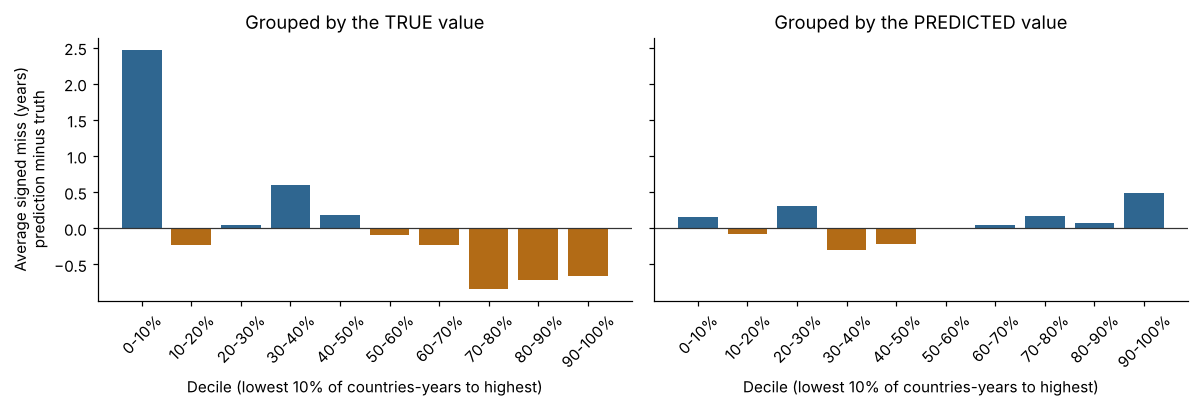

Lowest 10% by true value: predicted +2.47 years on average.   Highest 10%: -0.67 years.
Lowest 10% by predicted value: +0.16.   Highest 10%: +0.48.


In [3]:
oof["signed"] = oof["oof_prediction"] - oof["truth"]
oof["true_decile"] = pd.qcut(oof["truth"], 10, labels=[f"{i*10}-{i*10+10}%" for i in range(10)])
oof["pred_decile"] = pd.qcut(oof["oof_prediction"], 10, labels=[f"{i*10}-{i*10+10}%" for i in range(10)])
by_true = oof.groupby("true_decile", observed=True)["signed"].mean()
by_pred = oof.groupby("pred_decile", observed=True)["signed"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, s, title in [(axes[0], by_true, "Grouped by the TRUE value"), (axes[1], by_pred, "Grouped by the PREDICTED value")]:
    ax.bar(range(10), s.values, color=np.where(s.values < 0, "#B26B16", "#2F6690"))
    ax.axhline(0, color="#333", lw=0.8)
    ax.set(title=title, xticks=range(10), xticklabels=s.index, xlabel="Decile (lowest 10% of countries-years to highest)")
    ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("Average signed miss (years)\nprediction minus truth")
plt.tight_layout(); plt.show()
print(f"Lowest 10% by true value: predicted {by_true.iloc[0]:+.2f} years on average.   Highest 10%: {by_true.iloc[-1]:+.2f} years.")
print(f"Lowest 10% by predicted value: {by_pred.iloc[0]:+.2f}.   Highest 10%: {by_pred.iloc[-1]:+.2f}.")

**How to read it.** The data is split into ten equal slices from lowest life expectancy to highest. Each bar is the average *signed* miss in that slice: above zero means the model predicted too high, below zero too low. Left panel: sliced by the true value. Right panel: sliced by what the model predicted.

**What it means.** The left panel shows the pattern clearly: the countries with the shortest lives are predicted about 2.5 years too high, and the longest-lived about 0.6 years too low. That looks like something you could correct: "whenever the model predicts low, lower it a bit more".

The right panel is why you can't. When you slice by the *prediction* (which is all you have for a new country; you don't know the truth), the bias all but vanishes: every bar is under half a year. The model's low predictions are, on average, about right. The trouble is that among the countries the model predicts at 60, some are really at 50 and some at 70, and *it cannot tell which*. A correction based on the prediction would move all of them together and fix nothing.

In other words: the error is not a consistent lean that can be straightened out; it is genuine uncertainty about which countries are the extreme ones.

**What's next and why.** The project tested this directly rather than trusting the argument.

## Step 4: Trying to correct it anyway (the shrinkage check)

**What we are looking for.** The project fitted two kinds of after-the-fact correction, learned on one set of countries and tested on others, so the test is fair:

- **Linear:** stretch the predictions a little (prediction × slope + shift).
- **Isotonic:** a flexible curve that can bend the low predictions down and the high ones up, as much as the data supports.

In [4]:
shr = results("shrinkage_check")
rows = {"No correction": shr["A_raw"], "Linear stretch": shr["B_linear"], "Flexible curve (isotonic)": shr["C_isotonic"]}
pd.DataFrame({k: [v["mae"], v["r2"], v["bias_lowest_10pct"], v["bias_highest_10pct"], v["calibration_slope"]] for k, v in rows.items()},
             index=["Average miss (years)", "R²", "Bias, lowest 10% by truth", "Bias, highest 10% by truth", "Calibration slope"]).T

,Average miss (years),R²,"Bias, lowest 10% by truth","Bias, highest 10% by truth",Calibration slope
No correction,2.139,0.9047,-2.52,0.62,0.990
Linear stretch,2.143,0.9041,-2.68,0.76,0.999
Flexible curve (isotonic),2.207,0.8990,-2.75,1.02,0.998


**How to read it.** One row per approach. The first two columns are the overall scores; the next two are the bias at the extremes we were trying to fix (this file records truth minus prediction, so −2.5 means "predicted 2.5 years too high", the same fact as the +2.5 in Step 3); the calibration slope is 1.0 when predictions are neither too timid nor too bold overall.

**What it means.** Neither correction helps. The linear stretch does nothing (the slope was already 0.99, so there was nothing to stretch). The flexible curve makes the average miss *worse* (2.14 → 2.21 years) and the bias at the low end worse too (−2.5 → −2.8). This confirms Step 3: the extreme countries are not systematically mis-scaled; they are individually unpredictable from these 13 inputs.

**What's next and why.** Since the fix cannot come from post-processing, and notebook 7 will show it cannot come from a different algorithm either, the honest conclusion is that it has to come from *better information* about the hard countries: data on conflict, epidemics and reporting quality that the WHO table does not contain. Before that, notebook 6 asks a fairness question raised by this one: the hard countries are mostly developing countries. Is the model unfair to them?

## Summary

| Question | Answer |
| --- | --- |
| Is the error spread evenly? | No: the typical country is off by 2.0 years; the worst 10% carry 22% of all error |
| Who is hardest? | Somalia (11.5 yrs), Sierra Leone, Angola, Côte d'Ivoire, Swaziland: very short lives, conflict, epidemics. Korea and Cuba live longer than their numbers suggest |
| Is it missing data? | Only for Somalia (four inputs absent). Across countries, filled-in data does not predict error |
| Is there a pattern? | Yes, regression to the mean: lowest 10% predicted 2.5 yrs too high |
| Can it be corrected afterwards? | No: sliced by prediction the bias vanishes; fitted corrections make things worse |
| What would help? | Outside data on conflict, epidemics and reporting quality |